# 02 — Classical ML Models (TF-IDF)

> Part of a 5-notebook pipeline (run in order, each a separate kernel session — this is deliberate, see the note in the main README/first notebook):
> 1. `01_preprocessing_and_split.ipynb` — load, clean, dedupe, handle class imbalance, train/val/test split
> 2. `02_classical_ml.ipynb` — TF-IDF + Random Forest / Logistic Regression / Naive Bayes
> 3. `03_rnn_family.ipynb` — Word2Vec + SimpleRNN / GRU / LSTM (+ bidirectional variants)
> 4. `04_bert.ipynb` — BERT-base fine-tuning
> 5. `05_final_comparison.ipynb` — combined results across all 10 models
>
> **Why separate notebooks/kernels:** TensorFlow never releases GPU memory once it claims it, and PyTorch (used by BERT) initializing its own CUDA context in the same process can cause a hard, traceback-less kernel crash rather than a clean error. Keeping RNN training (TensorFlow) and BERT training (PyTorch) in different kernel processes avoids that entirely, and also caps how much of a crash costs you — a crash in notebook 4 no longer takes down anything from notebooks 1–3.
> All shared state (cleaned data, splits, trained models, results) is handed off between notebooks via files on disk, not kernel memory.

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_colwidth', 150)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1.1 Shared Result Tracking (persists across kernel restarts)

Some sections of this notebook (12, 13, 14) are expensive enough that you'll often run them in **separate kernel sessions** (e.g. restarting between the TensorFlow/RNN section and the PyTorch/BERT section to avoid the two frameworks fighting over the same GPU memory in one process — see the note in Section 14).

To make that safe, `tuning_log` (every hyperparameter run) and `final_results` (every model's final test-set metrics) are defined **once, here**, and every time a new entry is logged it's immediately saved to `tuning_log.csv` / `final_results.csv` on disk. At the top of each kernel session, this cell also **reloads whatever is already on disk**, so:
- Running only Sections 1–10 + 14 (BERT) in a fresh kernel still lets you log BERT results without a `NameError`.
- Results from an earlier kernel session (e.g. the RNN family) are still there when you get to Section 15, even though that code isn't in this session's memory.

**Run this cell every session**, right after the imports cell above, regardless of which later sections you plan to run.

In [2]:
import os
import pandas as pd

TUNING_LOG_PATH = 'tuning_log.csv'
FINAL_RESULTS_PATH = 'final_results.csv'

# Reload anything already saved from a previous kernel session, so results
# accumulate across restarts instead of resetting every time.
if os.path.exists(TUNING_LOG_PATH):
    tuning_log = pd.read_csv(TUNING_LOG_PATH).to_dict('records')
    print(f'Reloaded {len(tuning_log)} existing tuning_log rows from {TUNING_LOG_PATH}')
else:
    tuning_log = []

if os.path.exists(FINAL_RESULTS_PATH):
    final_results = pd.read_csv(FINAL_RESULTS_PATH).to_dict('records')
    print(f'Reloaded {len(final_results)} existing final_results rows from {FINAL_RESULTS_PATH}')
else:
    final_results = []


def log_run(model_name, config, val_acc, val_f1):
    """Record one hyperparameter run's validation metrics, print it, and persist immediately."""
    tuning_log.append({'model': model_name, 'config': str(config), 'val_accuracy': val_acc, 'val_f1_macro': val_f1})
    print(f"{model_name:22s} {str(config):55s} val_acc={val_acc:.4f}  val_f1_macro={val_f1:.4f}")
    pd.DataFrame(tuning_log).to_csv(TUNING_LOG_PATH, index=False)


def record_final_result(model_name, test_acc, f1_macro, f1_weighted):
    """Record one model's final test-set metrics and persist immediately."""
    # Overwrite any earlier entry for the same model name (e.g. re-running a section) rather than duplicating it.
    global final_results
    final_results = [r for r in final_results if r['model'] != model_name]
    final_results.append({'model': model_name, 'test_accuracy': test_acc, 'test_f1_macro': f1_macro, 'test_f1_weighted': f1_weighted})
    pd.DataFrame(final_results).to_csv(FINAL_RESULTS_PATH, index=False)


def best_config_row(df, model_name):
    """Given the tuning_log as a DataFrame, return the row with the best validation macro-F1 for one model."""
    sub = df[df['model'] == model_name]
    return sub.loc[sub['val_f1_macro'].idxmax()]

import hashlib
import ast

SAVED_MODELS_DIR = 'saved_models'
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'classical'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'rnn'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'bert'), exist_ok=True)


def _config_hash(config):
    """Short, deterministic filename-safe hash of a hyperparameter config dict."""
    return hashlib.md5(str(config).encode()).hexdigest()[:10]


def classical_model_path(model_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'classical', f'{model_name}__{_config_hash(config)}.joblib')


def rnn_model_path(arch_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'rnn', f'{arch_name}__{_config_hash(config)}.keras')


def bert_model_path(config):
    return os.path.join(SAVED_MODELS_DIR, 'bert', _config_hash(config))


def parse_config(config_str):
    """Turn the 'config' string stored in tuning_log back into a real dict, e.g. to
    reconstruct a saved-model path from a row of tuning_log_df / best_config_row()."""
    return ast.literal_eval(config_str)

## 0. Reload Pipeline State from Notebook 1

Run `01_preprocessing_and_split.ipynb` first if you haven't yet — this cell just reloads what it saved, so this notebook doesn't need that kernel to still be running.

In [3]:
import joblib

train_df = pd.read_csv('train_df.csv')
val_df = pd.read_csv('val_df.csv')
test_df = pd.read_csv('test_df.csv')

label_encoder = joblib.load('label_encoder.joblib')
class_weight_dict = joblib.load('class_weight_dict.joblib')
num_classes = len(label_encoder.classes_)

y_train = label_encoder.transform(train_df['category'])
y_val = label_encoder.transform(val_df['category'])
y_test = label_encoder.transform(test_df['category'])

print('Reloaded from Notebook 1:', train_df.shape, val_df.shape, test_df.shape, ' num_classes:', num_classes)

Reloaded from Notebook 1: (46697, 12) (10006, 12) (10007, 12)  num_classes: 6


### 11.1 TF-IDF

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3)

X_train_tfidf = tfidf_vectorizer.fit_transform(train_df['clean_summary'])
X_val_tfidf = tfidf_vectorizer.transform(val_df['clean_summary'])
X_test_tfidf = tfidf_vectorizer.transform(test_df['clean_summary'])

print('TF-IDF shapes -> train:', X_train_tfidf.shape, ' val:', X_val_tfidf.shape, ' test:', X_test_tfidf.shape)

TF-IDF shapes -> train: (46697, 20000)  val: (10006, 20000)  test: (10007, 20000)


## 12. Classical ML Models

Three models: **Random Forest**, **Logistic Regression**, **Naive Bayes** — all trained on the TF-IDF features. For each, we manually try **3 hyperparameter configurations**, evaluate each on the validation set (macro-F1, since it reflects performance across all classes equally despite the residual imbalance), log every run in a results table, then pick the best config per model and do the final evaluation on the untouched test set.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# tuning_log, log_run(), and best_config_row() are defined once in Section 1.1 (run that cell
# first if you haven't this session) so they persist across kernel restarts between sections.

def evaluate_on_val(model, X_val, y_val):
    pred = model.predict(X_val)
    return accuracy_score(y_val, pred), f1_score(y_val, pred, average='macro')

In [6]:
# ---- Random Forest: 3 configs ----
import joblib

rf_configs = [
    {'n_estimators': 100, 'max_depth': None},
    {'n_estimators': 300, 'max_depth': 40},
    {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2},
]

rf_models = {}
for cfg in rf_configs:
    path = classical_model_path('RandomForest', cfg)
    if os.path.exists(path):
        print(f'Already trained -- loading {path}')
        clf = joblib.load(path)
    else:
        clf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced', **cfg)
        clf.fit(X_train_tfidf, y_train)
        joblib.dump(clf, path)
        print(f'Trained and saved to {path}')
    acc, f1m = evaluate_on_val(clf, X_val_tfidf, y_val)
    log_run('RandomForest', cfg, acc, f1m)
    rf_models[str(cfg)] = clf

Trained and saved to saved_models/classical/RandomForest__ed7188d076.joblib
RandomForest           {'n_estimators': 100, 'max_depth': None}                val_acc=0.7208  val_f1_macro=0.7174
Trained and saved to saved_models/classical/RandomForest__e47df04109.joblib
RandomForest           {'n_estimators': 300, 'max_depth': 40}                  val_acc=0.7225  val_f1_macro=0.7149
Trained and saved to saved_models/classical/RandomForest__1dce76fbe1.joblib
RandomForest           {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2} val_acc=0.7266  val_f1_macro=0.7206


In [7]:
# ---- Logistic Regression: 3 configs ----
lr_configs = [
    {'C': 0.1, 'solver': 'lbfgs', 'max_iter': 1000},
    {'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000},
    {'C': 5.0, 'solver': 'saga', 'max_iter': 2000},
]

lr_models = {}
for cfg in lr_configs:
    path = classical_model_path('LogisticRegression', cfg)
    if os.path.exists(path):
        print(f'Already trained -- loading {path}')
        clf = joblib.load(path)
    else:
        clf = LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE, **cfg)
        clf.fit(X_train_tfidf, y_train)
        joblib.dump(clf, path)
        print(f'Trained and saved to {path}')
    acc, f1m = evaluate_on_val(clf, X_val_tfidf, y_val)
    log_run('LogisticRegression', cfg, acc, f1m)
    lr_models[str(cfg)] = clf

Trained and saved to saved_models/classical/LogisticRegression__2880cc8e2e.joblib
LogisticRegression     {'C': 0.1, 'solver': 'lbfgs', 'max_iter': 1000}         val_acc=0.7472  val_f1_macro=0.7467
Trained and saved to saved_models/classical/LogisticRegression__43399c2aa2.joblib
LogisticRegression     {'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000}         val_acc=0.7618  val_f1_macro=0.7629
Trained and saved to saved_models/classical/LogisticRegression__8c0f3b994d.joblib
LogisticRegression     {'C': 5.0, 'solver': 'saga', 'max_iter': 2000}          val_acc=0.7438  val_f1_macro=0.7467


In [8]:
# ---- Naive Bayes: 3 configs ----
# MultinomialNB has no native class_weight param; we approximate class balancing via `sample_weight` at fit time.
from sklearn.utils.class_weight import compute_sample_weight
sample_weights_train = compute_sample_weight('balanced', y_train)

nb_configs = [
    {'alpha': 0.1},
    {'alpha': 0.5},
    {'alpha': 1.0},
]

nb_models = {}
for cfg in nb_configs:
    path = classical_model_path('NaiveBayes', cfg)
    if os.path.exists(path):
        print(f'Already trained -- loading {path}')
        clf = joblib.load(path)
    else:
        clf = MultinomialNB(**cfg)
        clf.fit(X_train_tfidf, y_train, sample_weight=sample_weights_train)
        joblib.dump(clf, path)
        print(f'Trained and saved to {path}')
    acc, f1m = evaluate_on_val(clf, X_val_tfidf, y_val)
    log_run('NaiveBayes', cfg, acc, f1m)
    nb_models[str(cfg)] = clf

Trained and saved to saved_models/classical/NaiveBayes__04f74f957c.joblib
NaiveBayes             {'alpha': 0.1}                                          val_acc=0.7430  val_f1_macro=0.7425
Trained and saved to saved_models/classical/NaiveBayes__223fdb7ae0.joblib
NaiveBayes             {'alpha': 0.5}                                          val_acc=0.7454  val_f1_macro=0.7430
Trained and saved to saved_models/classical/NaiveBayes__b99b020128.joblib
NaiveBayes             {'alpha': 1.0}                                          val_acc=0.7436  val_f1_macro=0.7403


In [9]:
tuning_log_df = pd.DataFrame(tuning_log)
tuning_log_df

,model,config,val_accuracy,val_f1_macro
0,RandomForest,"{'n_estimators': 100, 'max_depth': None}",0.720768,0.717429
1,RandomForest,"{'n_estimators': 300, 'max_depth': 40}",0.722467,0.714878
2,RandomForest,"{'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2}",0.726564,0.720621
3,LogisticRegression,"{'C': 0.1, 'solver': 'lbfgs', 'max_iter': 1000}",0.747152,0.746716
4,LogisticRegression,"{'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000}",0.761843,0.762877
5,LogisticRegression,"{'C': 5.0, 'solver': 'saga', 'max_iter': 2000}",0.743754,0.746717
6,NaiveBayes,{'alpha': 0.1},0.742954,0.742495
7,NaiveBayes,{'alpha': 0.5},0.745353,0.742990
8,NaiveBayes,{'alpha': 1.0},0.743554,0.740266


Pick the best configuration per model family (highest validation macro-F1), then do the one-shot final evaluation on the held-out **test** set:

Best config for RandomForest: {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2}  (val_f1_macro=0.7206)
=== RandomForest (test set) ===
Accuracy: 0.7238   Macro-F1: 0.7191   Weighted-F1: 0.7124
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.73      0.61      0.67      1800
Computation and Language (Natural Language Processing)       0.75      0.86      0.80      1800
               Computer Vision and Pattern Recognition       0.79      0.90      0.84      1800
                                      Machine Learning       0.62      0.39      0.48      1800
                         Machine Learning (Statistics)       0.65      0.80      0.72      1800
                     Neural and Evolutionary Computing       0.79      0.82      0.80      1007

                                              accuracy                           0.72     10007
                       

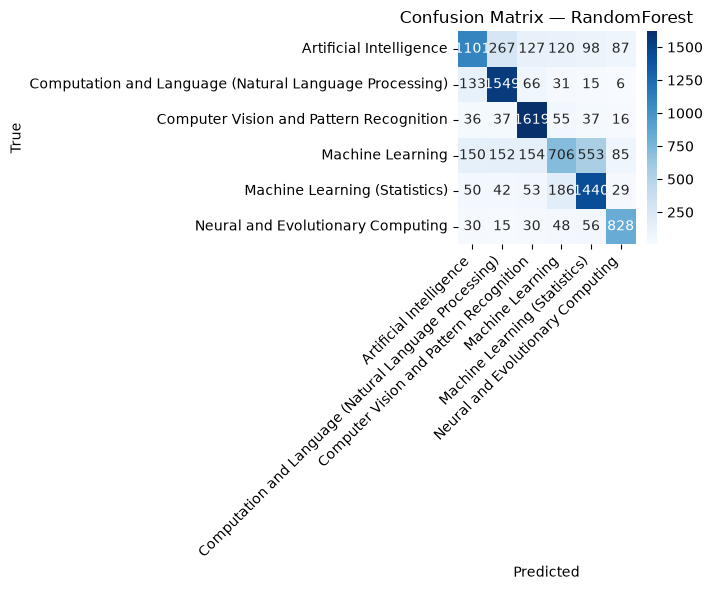

Best config for LogisticRegression: {'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000}  (val_f1_macro=0.7629)
=== LogisticRegression (test set) ===
Accuracy: 0.7539   Macro-F1: 0.7563   Weighted-F1: 0.7522
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.72      0.70      0.71      1800
Computation and Language (Natural Language Processing)       0.82      0.83      0.82      1800
               Computer Vision and Pattern Recognition       0.87      0.88      0.88      1800
                                      Machine Learning       0.60      0.55      0.57      1800
                         Machine Learning (Statistics)       0.72      0.78      0.75      1800
                     Neural and Evolutionary Computing       0.79      0.82      0.81      1007

                                              accuracy                           0.75     10007
                           

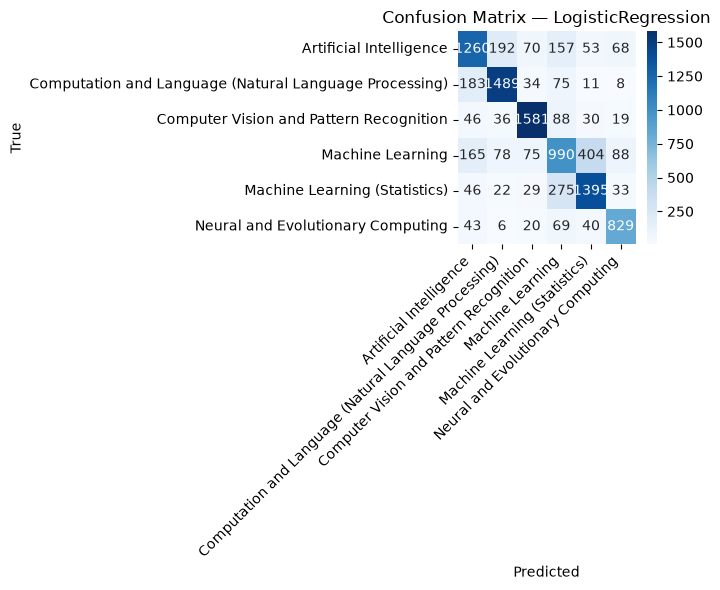

Best config for NaiveBayes: {'alpha': 0.5}  (val_f1_macro=0.7430)
=== NaiveBayes (test set) ===
Accuracy: 0.7412   Macro-F1: 0.7398   Weighted-F1: 0.7359
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.70      0.69      0.69      1800
Computation and Language (Natural Language Processing)       0.82      0.83      0.82      1800
               Computer Vision and Pattern Recognition       0.86      0.86      0.86      1800
                                      Machine Learning       0.64      0.47      0.54      1800
                         Machine Learning (Statistics)       0.68      0.80      0.74      1800
                     Neural and Evolutionary Computing       0.74      0.85      0.79      1007

                                              accuracy                           0.74     10007
                                             macro avg       0.74      0.75 

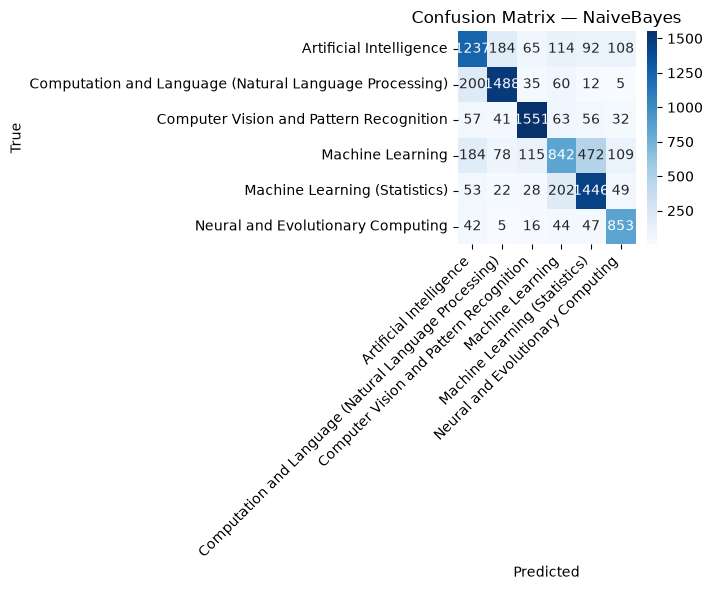

In [10]:
# best_config_row() is already defined in Section 1.1. final_results is also already
# defined there (and persisted to final_results.csv) so it survives kernel restarts.
classical_models = {'RandomForest': rf_models, 'LogisticRegression': lr_models, 'NaiveBayes': nb_models}

def evaluate_on_test(model_name, model, X_test, y_test, label_encoder):
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    f1_macro = f1_score(y_test, pred, average='macro')
    f1_weighted = f1_score(y_test, pred, average='weighted')
    cm = confusion_matrix(y_test, pred)
    report = classification_report(y_test, pred, target_names=label_encoder.classes_)

    print(f'=== {model_name} (test set) ===')
    print(f'Accuracy: {acc:.4f}   Macro-F1: {f1_macro:.4f}   Weighted-F1: {f1_weighted:.4f}')
    print(report)

    plt.figure(figsize=(7,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    plt.title(f'Confusion Matrix — {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    record_final_result(model_name, acc, f1_macro, f1_weighted)
    return pred

for model_name, model_dict in classical_models.items():
    best_row = best_config_row(tuning_log_df, model_name)
    best_cfg = parse_config(best_row['config'])
    path = classical_model_path(model_name, best_cfg)
    best_model = model_dict.get(best_row['config']) or joblib.load(path)  # falls back to disk if this dict is from a fresh kernel
    print(f'Best config for {model_name}: {best_row["config"]}  (val_f1_macro={best_row["val_f1_macro"]:.4f})')
    evaluate_on_test(model_name, best_model, X_test_tfidf, y_test, label_encoder)